<a href="https://colab.research.google.com/github/gayatri479/CSA4705-Deep-learning-B-SLOT/blob/main/CO-4-LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 49 – RNN-based sentiment classification

A small demonstration dataset of positive and negative product reviews is tokenized and classified.

In [5]:
reviews = [
"I love this product it works perfectly","excellent quality and fast delivery","very happy with this purchase","great value and amazing design","the product is wonderful","easy to use and reliable","highly recommend this item","fantastic experience and good quality",
"this is the best product","works very well and looks great","good product for the price","delivery was quick and item is perfect",
"I hate this product it is terrible","very poor quality and bad service","waste of money and time","the product stopped working","disappointed with this purchase","not worth the price","bad design and difficult to use","I will not recommend this item",
"terrible experience and slow delivery","the product is broken","poor performance and unreliable","completely unhappy with this item"
]
labels = np.array([1]*12+[0]*12)
vectorizer = layers.TextVectorization(max_tokens=1000,output_sequence_length=12)
vectorizer.adapt(reviews)
X = vectorizer(np.array(reviews))
X_train,X_test,y_train,y_test = train_test_split(X.numpy(),labels,test_size=0.25,random_state=42,stratify=labels)
model = models.Sequential([layers.Input((12,),dtype="int64"),layers.Embedding(1000,32),layers.SimpleRNN(32),layers.Dense(16,activation="relu"),layers.Dense(1,activation="sigmoid")])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=15,batch_size=4,verbose=1)
loss,acc = model.evaluate(X_test,y_test,verbose=0)
print("Test accuracy:",acc)
samples = ["excellent product and wonderful quality","poor product and terrible experience"]
print(list(zip(samples,(model.predict(vectorizer(samples),verbose=0).flatten()>0.5).astype(int))))

Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5000 - loss: 0.7146
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7222 - loss: 0.6751
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8889 - loss: 0.6571
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8889 - loss: 0.6303
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9444 - loss: 0.5923
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.5416
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.4711
Epoch 8/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.3764
Epoch 9/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.2610
Epoch 10/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.1656
Epoch 11/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.0979
Epoch 12/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.0645
E

## Experiment 50 – Character-level RNN text generation

The model learns character patterns from a short training text and generates a new character sequence.

In [9]:
import numpy as np
from tensorflow.keras import models, layers

text_data = ("deep learning uses neural networks. recurrent neural networks learn from sequences. "
             "language models predict the next character from previous characters. ")*30
chars = sorted(set(text_data))
char_to_id = {c:i for i,c in enumerate(chars)}
id_to_char = np.array(chars)
seq_len = 40
encoded = np.array([char_to_id[c] for c in text_data])
X = np.array([encoded[i:i+seq_len] for i in range(len(encoded)-seq_len)])
y = encoded[seq_len:]
model = models.Sequential([layers.Input((seq_len,)),layers.Embedding(len(chars),48),layers.SimpleRNN(96),layers.Dense(len(chars),activation="softmax")])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy")
model.fit(X,y,epochs=8,batch_size=64,verbose=1)
seed = "recurrent neural networks learn from "
generated = seed
for _ in range(250):
    ids = np.array([[char_to_id.get(c,0) for c in generated[-seq_len:]]])
    probs = model.predict(ids,verbose=0)[0]
    next_id = np.random.choice(len(chars),p=probs/probs.sum())
    generated += id_to_char[next_id]
print(generated)

Epoch 1/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 2.2448
Epoch 2/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0034
Epoch 3/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.3183
Epoch 4/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0992
Epoch 5/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0474
Epoch 6/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0285
Epoch 7/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0192
Epoch 8/8
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0139
recurrent neural networks learn from lnquences. language models lredict lhe selt character nrom prevmott charkct t lxa ep leurninsonses neuralieetlid sr ltxweresg s trawaonrwp.nsw ieaw terrse teteensanqudelf vrerglucknegeeuesetwrnd paesaonectkdreeodhrese dct ue fat oeknt treuweu usor kd


## Experiment 51 – RNN time-series forecasting for stock values

Generated historical stock-like prices are used to train an RNN and evaluate forecasting accuracy.

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0022 - val_loss: 8.3723e-04
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1283e-04 - val_loss: 5.4583e-04
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 4.7665e-04 - val_loss: 0.0016
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.5288e-04 - val_loss: 6.9944e-04
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.9971e-04 - val_loss: 9.5989e-04
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 4.5523e-04 - val_loss: 3.5483e-04
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.9602e-04 - val_loss: 7.2633e-04
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.9297e-04 - val_loss: 7.6471e-04
Epoch 9/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.8749e-04 - val_loss: 5.7777e-04
Epoch 10/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.9627e-04 - val_loss: 3.3405e-04
MAE: 0.9597453474998474
RMSE: 1.1965077227619416


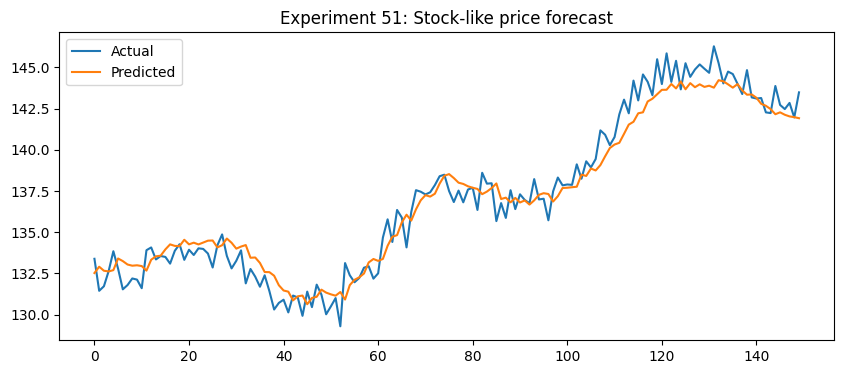

In [8]:
from sklearn.metrics import mean_squared_error

steps = np.arange(1800)
prices = (100 + 0.025*steps + 5*np.sin(steps/35) + 2*np.sin(steps/8) + np.random.normal(0,0.8,len(steps))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(prices.reshape(-1,1)).flatten()
window = 40
X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
y = np.array([z[i+window] for i in range(len(z)-window)])
cut = int(0.8*len(X))
model = models.Sequential([layers.Input((window,1)),layers.SimpleRNN(48),layers.Dense(24,activation="relu"),layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
model.fit(X[:cut],y[:cut],epochs=10,batch_size=32,validation_split=0.1,verbose=1)
pred = scaler.inverse_transform(model.predict(X[cut:],verbose=0))
actual = scaler.inverse_transform(y[cut:].reshape(-1,1))
print("MAE:",mean_absolute_error(actual,pred))
print("RMSE:",np.sqrt(mean_squared_error(actual,pred)))
plt.figure(figsize=(10,4))
plt.plot(actual[:150],label="Actual")
plt.plot(pred[:150],label="Predicted")
plt.legend()
plt.title("Experiment 51: Stock-like price forecast")
plt.show()

## Experiment 52 – RNN electricity consumption forecasting

Daily electricity demand is generated with trend, weekly pattern, and noise. The RNN forecasts future demand.

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0457 - mae: 0.1391 - val_loss: 0.0077 - val_mae: 0.0709
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0049 - mae: 0.0561 - val_loss: 0.0057 - val_mae: 0.0611
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0045 - mae: 0.0536 - val_loss: 0.0044 - val_mae: 0.0531
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0039 - mae: 0.0499 - val_loss: 0.0048 - val_mae: 0.0562
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0037 - mae: 0.0488 - val_loss: 0.0035 - val_mae: 0.0467
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0034 - mae: 0.0464 - val_loss: 0.0030 - val_mae: 0.0440
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0034 - mae: 0.0467 - val_loss: 0.0042 - val_mae: 0.0533
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0032 - mae: 0.0449 - val_loss: 0.0028 - val_mae: 0.0419
Epoch 9/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0030 - mae

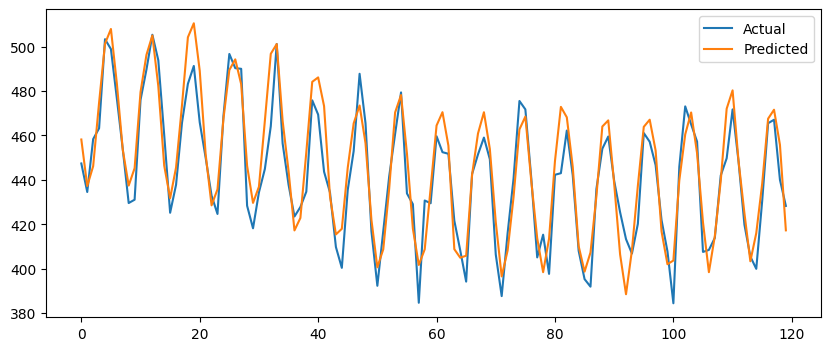

In [10]:
d = np.arange(1600)
demand = (450 + 35*np.sin(2*np.pi*d/7) + 55*np.sin(2*np.pi*d/365) + 0.025*d + np.random.normal(0,10,len(d))).astype("float32")
scaler = MinMaxScaler()
v = scaler.fit_transform(demand.reshape(-1,1)).flatten()
window = 28
X = np.array([v[i:i+window] for i in range(len(v)-window)])[...,None]
y = np.array([v[i+window] for i in range(len(v)-window)])
cut = int(.8*len(X))
model = models.Sequential([layers.Input((window,1)),layers.SimpleRNN(40),layers.Dense(1)])
model.compile(optimizer="adam",loss="mse",metrics=["mae"])
model.fit(X[:cut],y[:cut],epochs=10,batch_size=32,validation_split=.1,verbose=1)
p = scaler.inverse_transform(model.predict(X[cut:],verbose=0))
a = scaler.inverse_transform(y[cut:].reshape(-1,1))
print("MAE:",mean_absolute_error(a,p))
print("Forecast for next day:",float(scaler.inverse_transform(model.predict(v[-window:][None,:,None],verbose=0))[0,0]))
plt.figure(figsize=(10,4))
plt.plot(a[:120],label="Actual")
plt.plot(p[:120],label="Predicted")
plt.legend()
plt.show()

## Experiment 53 – RNN next-word prediction

A word-level RNN learns a small sample text and predicts a likely next word from a short input sequence.

In [11]:
corpus = ("deep learning models learn patterns from data. recurrent neural networks process sequence data. "
          "language models predict the next word in a sentence. neural networks are useful for text prediction. ")*40
tokens = corpus.lower().replace(".","").split()
vocab = sorted(set(tokens))
word_to_id = {w:i+1 for i,w in enumerate(vocab)}
id_to_word = {i:w for w,i in word_to_id.items()}
seq_len = 5
encoded = [word_to_id[w] for w in tokens]
X = np.array([encoded[i:i+seq_len] for i in range(len(encoded)-seq_len)])
y = np.array([encoded[i+seq_len] for i in range(len(encoded)-seq_len)])
model = models.Sequential([layers.Input((seq_len,)),layers.Embedding(len(vocab)+1,32),layers.SimpleRNN(64),layers.Dense(len(vocab)+1,activation="softmax")])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X,y,epochs=12,batch_size=32,verbose=1)
prompt = "recurrent neural networks process sequence"
ids = [word_to_id.get(w,0) for w in prompt.split()[-seq_len:]]
probs = model.predict(np.array([ids]),verbose=0)[0]
print("Input:",prompt)
print("Predicted next word:",id_to_word.get(int(np.argmax(probs)),"unknown"))
print("Training accuracy:",model.evaluate(X,y,verbose=0)[1])

Epoch 1/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7186 - loss: 2.7505
Epoch 2/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9801 - loss: 0.9320
Epoch 3/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.1915
Epoch 4/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0757
Epoch 5/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0445
Epoch 6/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0303
Epoch 7/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0224
Epoch 8/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0173
Epoch 9/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0138
Epoch 10/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0114
Epoch 11/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0096
Epoch 12/12
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - lo

## Experiment 54 – Compare RNN and LSTM for product demand forecasting

Both models use the same generated product-sales dataset, sequence window, and chronological split.

In [14]:
import pandas as pd

q = np.arange(1400)
sales = (200 + 22*np.sin(2*np.pi*q/7) + 30*np.sin(q/45) + .015*q + np.random.normal(0,6,len(q))).astype("float32")
scaler = MinMaxScaler()
s = scaler.fit_transform(sales.reshape(-1,1)).flatten()
window = 21
X = np.array([s[i:i+window] for i in range(len(s)-window)])[...,None]
y = np.array([s[i+window] for i in range(len(s)-window)])
cut = int(.8*len(X))
results = {}
for name, recurrent in [("RNN",layers.SimpleRNN(32)),("LSTM",layers.LSTM(32))]:
    net = models.Sequential([layers.Input((window,1)),recurrent,layers.Dense(1)])
    net.compile(optimizer="adam",loss="mse")
    net.fit(X[:cut],y[:cut],epochs=8,batch_size=32,verbose=0)
    p = scaler.inverse_transform(net.predict(X[cut:],verbose=0))
    a = scaler.inverse_transform(y[cut:].reshape(-1,1))
    results[name] = (mean_absolute_error(a,p),np.sqrt(mean_squared_error(a,p)))
print(pd.DataFrame(results,index=["MAE","RMSE"]).T)

            MAE       RMSE
RNN    6.798726   8.670390
LSTM  14.943128  17.414013


## Experiment 55 – LSTM stock-price prediction

An LSTM model predicts stock-like prices from historical observations and reports regression metrics.

Epoch 1/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0248 - val_loss: 6.3183e-04
Epoch 2/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0031 - val_loss: 0.0013
Epoch 3/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0019 - val_loss: 7.9097e-04
Epoch 4/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0016 - val_loss: 0.0017
Epoch 5/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0016 - val_loss: 8.0298e-04
Epoch 6/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0012 - val_loss: 6.7817e-04
Epoch 7/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0012 - val_loss: 0.0015
Epoch 8/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0012 - val_loss: 0.0048
Epoch 9/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0012 - val_loss: 4.6654e-04
Epoch 10/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0011 - val_loss: 6.2177e-04
Epoch 11/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 9.3302e-04 - val_loss: 5.8370e-04
Epoch 12/12
38/38 ━━━━━━━━━━━━━

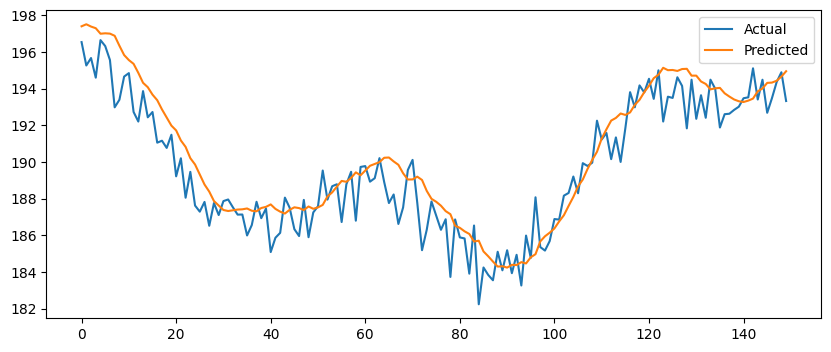

In [12]:
k = np.arange(1700)
stock = (150 + .03*k + 7*np.sin(k/40) + 2.5*np.sin(k/9) + np.random.normal(0,1,len(k))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(stock.reshape(-1,1)).flatten()
window = 35
X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
y = np.array([z[i+window] for i in range(len(z)-window)])
cut = int(.8*len(X))
model = models.Sequential([layers.Input((window,1)),layers.LSTM(64),layers.Dropout(.2),layers.Dense(32,activation="relu"),layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
model.fit(X[:cut],y[:cut],epochs=12,batch_size=32,validation_split=.1,verbose=1)
p = scaler.inverse_transform(model.predict(X[cut:],verbose=0))
a = scaler.inverse_transform(y[cut:].reshape(-1,1))
print("MAE:",mean_absolute_error(a,p))
print("MSE:",mean_squared_error(a,p))
print("RMSE:",np.sqrt(mean_squared_error(a,p)))
plt.figure(figsize=(10,4))
plt.plot(a[:150],label="Actual")
plt.plot(p[:150],label="Predicted")
plt.legend()
plt.show()

## Experiment 56 – GRU multivariate weather forecasting

Temperature, humidity, and pressure are used together to predict the next temperature value.

In [15]:
t = np.arange(1800)
weather = np.column_stack([
    25 + 6*np.sin(2*np.pi*t/365) + np.random.normal(0,.5,len(t)),
    60 + 12*np.sin(2*np.pi*t/90) + np.random.normal(0,2,len(t)),
    1010 + 8*np.sin(2*np.pi*t/180) + np.random.normal(0,1.5,len(t))
]).astype("float32")
scaler = MinMaxScaler()
w = scaler.fit_transform(weather)
window = 24
X = np.array([w[i:i+window] for i in range(len(w)-window)])
y = np.array([w[i+window,0] for i in range(len(w)-window)])
cut = int(.8*len(X))
model = models.Sequential([layers.Input((window,3)),layers.GRU(48),layers.Dense(24,activation="relu"),layers.Dense(1)])
model.compile(optimizer="adam",loss="mse",metrics=["mae"])
model.fit(X[:cut],y[:cut],epochs=12,batch_size=32,validation_split=.1,verbose=1)
p = model.predict(X[cut:],verbose=0).flatten()
print("Scaled MAE:",mean_absolute_error(y[cut:],p))
print("Next temperature forecast:",float(scaler.inverse_transform(np.array([[model.predict(w[-window:][None,:,:],verbose=0)[0,0],0,0]]))[0,0]))

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.1027 - mae: 0.2428 - val_loss: 0.0164 - val_mae: 0.1133
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0071 - mae: 0.0647 - val_loss: 0.0021 - val_mae: 0.0367
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0022 - mae: 0.0373 - val_loss: 0.0012 - val_mae: 0.0273
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0018 - mae: 0.0337 - val_loss: 0.0012 - val_mae: 0.0273
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0017 - mae: 0.0327 - val_loss: 0.0012 - val_mae: 0.0277
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0017 - mae: 0.0330 - val_loss: 0.0012 - val_mae: 0.0275
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0017 - mae: 0.0327 - val_loss: 0.0012 - val_mae: 0.0275
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0017 - mae: 0.0325 - val_loss: 0.0012 - val_mae: 0.0280
Epoch 9/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.001

## Experiment 57 – Compare RNN, LSTM, and GRU architectures

All three recurrent architectures are trained on the same sequence prediction task.

In [16]:
u = np.arange(1300)
series = (2 + .7*np.sin(u/20) + .25*np.sin(u/5) + np.random.normal(0,.06,len(u))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(series.reshape(-1,1)).flatten()
window = 25
X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
y = np.array([z[i+window] for i in range(len(z)-window)])
cut = int(.8*len(X))
results = {}
for name, recurrent in [("RNN",layers.SimpleRNN(40)),("LSTM",layers.LSTM(40)),("GRU",layers.GRU(40))]:
    net = models.Sequential([layers.Input((window,1)),recurrent,layers.Dense(1)])
    net.compile(optimizer="adam",loss="mse")
    net.fit(X[:cut],y[:cut],epochs=8,batch_size=32,verbose=0)
    pred = net.predict(X[cut:],verbose=0).flatten()
    results[name] = [mean_absolute_error(y[cut:],pred),np.sqrt(mean_squared_error(y[cut:],pred))]
print(pd.DataFrame(results,index=["MAE","RMSE"]).T)

           MAE      RMSE
RNN   0.040959  0.052875
LSTM  0.050183  0.062083
GRU   0.044459  0.055476


## Experiment 58 – Stacked RNN for multivariate machine condition prediction

Temperature, pressure, and vibration are used as input features. A stacked RNN predicts the next temperature reading.

In [17]:
t = np.arange(1500)
machine = np.column_stack([
    65 + 5*np.sin(t/30) + np.random.normal(0,1,len(t)),
    3 + .4*np.sin(t/18) + np.random.normal(0,.08,len(t)),
    1.5 + .3*np.sin(t/7) + np.random.normal(0,.07,len(t))
]).astype("float32")
scaler = MinMaxScaler()
m = scaler.fit_transform(machine)
window = 20
X = np.array([m[i:i+window] for i in range(len(m)-window)])
y = np.array([m[i+window,0] for i in range(len(m)-window)])
cut = int(.8*len(X))
model = models.Sequential([layers.Input((window,3)),layers.SimpleRNN(48,return_sequences=True),layers.SimpleRNN(24),layers.Dense(16,activation="relu"),layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
model.fit(X[:cut],y[:cut],epochs=10,batch_size=32,validation_split=.1,verbose=1)
p = model.predict(X[cut:],verbose=0).flatten()
print("Scaled MAE:",mean_absolute_error(y[cut:],p))
print("Scaled RMSE:",np.sqrt(mean_squared_error(y[cut:],p)))

Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0346 - val_loss: 0.0119
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0098 - val_loss: 0.0092
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0086 - val_loss: 0.0061
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0079 - val_loss: 0.0075
Epoch 5/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0067 - val_loss: 0.0062
Epoch 6/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0066 - val_loss: 0.0062
Epoch 7/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0065 - val_loss: 0.0074
Epoch 8/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0065 - val_loss: 0.0080
Epoch 9/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0064 - val_loss: 0.0065
Epoch 10/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0063 - val_loss: 0.0062
Scaled MAE: 0.06194528937339783
Scaled RMSE: 0.07693377338629594


## Experiment 59 – Demonstrate the vanishing gradient problem

Gradients are calculated through repeated multiplication by a recurrent weight. Values shrink as the number of time steps increases.

Time steps:  1 | Gradient: 0.5000000000
Time steps:  2 | Gradient: 0.2500000000
Time steps:  3 | Gradient: 0.1250000000
Time steps:  4 | Gradient: 0.0625000000
Time steps:  5 | Gradient: 0.0312500000
Time steps:  6 | Gradient: 0.0156250000
Time steps:  7 | Gradient: 0.0078125000
Time steps:  8 | Gradient: 0.0039062500
Time steps:  9 | Gradient: 0.0019531250
Time steps: 10 | Gradient: 0.0009765625
Time steps: 11 | Gradient: 0.0004882812
Time steps: 12 | Gradient: 0.0002441406
Time steps: 13 | Gradient: 0.0001220703
Time steps: 14 | Gradient: 0.0000610352
Time steps: 15 | Gradient: 0.0000305176
Time steps: 16 | Gradient: 0.0000152588
Time steps: 17 | Gradient: 0.0000076294
Time steps: 18 | Gradient: 0.0000038147
Time steps: 19 | Gradient: 0.0000019073
Time steps: 20 | Gradient: 0.0000009537
Time steps: 21 | Gradient: 0.0000004768
Time steps: 22 | Gradient: 0.0000002384
Time steps: 23 | Gradient: 0.0000001192
Time steps: 24 | Gradient: 0.0000000596
Time steps: 25 | Gradient: 0.0000000298


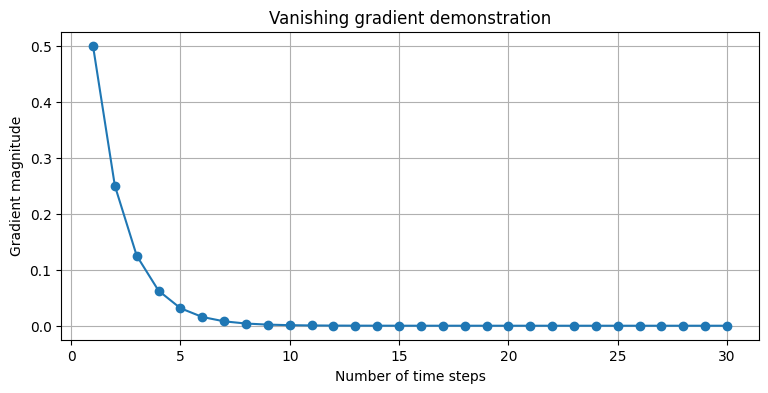

Initial gradient: 0.5
Gradient after 30 steps: 9.313225746154785e-10


In [18]:
steps = np.arange(1,31)
weight = 0.5
gradients = weight**steps
for step, grad in zip(steps,gradients):
    print(f"Time steps: {step:2d} | Gradient: {grad:.10f}")
plt.figure(figsize=(9,4))
plt.plot(steps,gradients,marker="o")
plt.xlabel("Number of time steps")
plt.ylabel("Gradient magnitude")
plt.title("Vanishing gradient demonstration")
plt.grid(True)
plt.show()
print("Initial gradient:",gradients[0])
print("Gradient after 30 steps:",gradients[-1])

## Experiment 60 – Analyse different RNN sequence lengths

The same temperature series is evaluated with different historical input window sizes.

   Sequence Length       MAE
0                5  0.046040
1               10  0.042237
2               20  0.044541
3               30  0.037503
4               45  0.041442


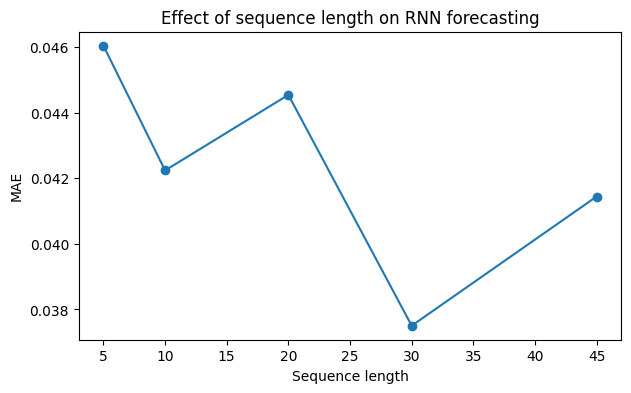

In [19]:
t = np.arange(1200)
temp = (28 + 4*np.sin(t/55) + .8*np.sin(t/8) + np.random.normal(0,.4,len(t))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(temp.reshape(-1,1)).flatten()
results = {}
for window in [5,10,20,30,45]:
    X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
    y = np.array([z[i+window] for i in range(len(z)-window)])
    cut = int(.8*len(X))
    net = models.Sequential([layers.Input((window,1)),layers.SimpleRNN(32),layers.Dense(1)])
    net.compile(optimizer="adam",loss="mse")
    net.fit(X[:cut],y[:cut],epochs=6,batch_size=32,verbose=0)
    p = net.predict(X[cut:],verbose=0).flatten()
    results[window] = mean_absolute_error(y[cut:],p)
print(pd.DataFrame({"Sequence Length":list(results.keys()),"MAE":list(results.values())}))
plt.figure(figsize=(7,4))
plt.plot(list(results.keys()),list(results.values()),marker="o")
plt.xlabel("Sequence length")
plt.ylabel("MAE")
plt.title("Effect of sequence length on RNN forecasting")
plt.show()

## Experiment 61 – LSTM hyperparameter tuning

Different learning rates, hidden-unit counts, and batch sizes are tested on the same product-demand sequence.

In [20]:
t = np.arange(1000)
demand = (100 + 15*np.sin(t/20) + 5*np.sin(t/5) + np.random.normal(0,2,len(t))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(demand.reshape(-1,1)).flatten()
window = 20
X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
y = np.array([z[i+window] for i in range(len(z)-window)])
cut = int(.8*len(X))
results = []
for lr in [0.001,0.005]:
    for units in [24,48]:
        for batch in [16,32]:
            net = models.Sequential([layers.Input((window,1)),layers.LSTM(units),layers.Dense(1)])
            net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),loss="mse")
            net.fit(X[:cut],y[:cut],epochs=5,batch_size=batch,verbose=0)
            p = net.predict(X[cut:],verbose=0).flatten()
            results.append([lr,units,batch,mean_absolute_error(y[cut:],p)])
result_df = pd.DataFrame(results,columns=["Learning Rate","Hidden Units","Batch Size","MAE"])
print(result_df.sort_values("MAE").to_string(index=False))
print("Best configuration:")
print(result_df.loc[result_df["MAE"].idxmin()].to_dict())

 Learning Rate  Hidden Units  Batch Size      MAE
         0.005            24          16 0.043134
         0.005            48          32 0.044889
         0.005            48          16 0.047838
         0.005            24          32 0.050345
         0.001            24          16 0.056981
         0.001            48          16 0.063890
         0.001            48          32 0.077733
         0.001            24          32 0.080791
Best configuration:
{'Learning Rate': 0.005, 'Hidden Units': 24.0, 'Batch Size': 16.0, 'MAE': 0.043133825063705444}


## Experiment 62 – Evaluate RNN using MAE, MSE, and RMSE

An RNN forecasts electricity consumption and its prediction errors are calculated.

In [21]:
t = np.arange(1300)
energy = (350 + 25*np.sin(2*np.pi*t/7) + 40*np.sin(t/60) + np.random.normal(0,5,len(t))).astype("float32")
scaler = MinMaxScaler()
z = scaler.fit_transform(energy.reshape(-1,1)).flatten()
window = 21
X = np.array([z[i:i+window] for i in range(len(z)-window)])[...,None]
y = np.array([z[i+window] for i in range(len(z)-window)])
cut = int(.8*len(X))
net = models.Sequential([layers.Input((window,1)),layers.SimpleRNN(40),layers.Dense(1)])
net.compile(optimizer="adam",loss="mse")
net.fit(X[:cut],y[:cut],epochs=10,batch_size=32,verbose=1)
p = scaler.inverse_transform(net.predict(X[cut:],verbose=0))
a = scaler.inverse_transform(y[cut:].reshape(-1,1))
mae = mean_absolute_error(a,p)
mse = mean_squared_error(a,p)
rmse = np.sqrt(mse)
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0183
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0029
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0026
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0025
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0023
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022
Epoch 9/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0022
Epoch 10/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0021
MAE: 4.914029121398926
MSE: 36.379364013671875
RMSE: 6.031530818430084


## Experiment 63 – Evaluate complaint message classification using precision, recall, and F1-score

An RNN classifies customer messages into delivery, payment, product, and account complaints.

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

messages = [
"my parcel is delayed","delivery has not arrived","where is my shipment","late delivery service","package tracking is not updated",
"payment failed during checkout","money was deducted twice","refund for failed payment","charged extra amount","payment gateway problem",
"the product is damaged","item received is broken","wrong product delivered","product quality is poor","missing parts in product",
"cannot login to account","password reset is not working","account is locked","unable to update profile","otp is not received"
]
labels_text = ["delivery"]*5+["payment"]*5+["product"]*5+["account"]*5
label_names = sorted(set(labels_text))
label_map = {name:i for i,name in enumerate(label_names)}
y = np.array([label_map[x] for x in labels_text])
vectorizer = layers.TextVectorization(max_tokens=1000,output_sequence_length=12)
vectorizer.adapt(messages)
X = vectorizer(np.array(messages))
X_train,X_test,y_train,y_test = train_test_split(X.numpy(),y,test_size=.3,random_state=42,stratify=y)
net = models.Sequential([layers.Input((12,),dtype="int64"),layers.Embedding(1000,32),layers.SimpleRNN(32),layers.Dense(24,activation="relu"),layers.Dense(len(label_names),activation="softmax")])
net.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
net.fit(X_train,y_train,epochs=20,batch_size=4,verbose=1)
pred = np.argmax(net.predict(X_test,verbose=0),axis=1)
print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred,average="macro",zero_division=0))
print("Recall:",recall_score(y_test,pred,average="macro",zero_division=0))
print("F1-score:",f1_score(y_test,pred,average="macro",zero_division=0))
print(classification_report(y_test,pred,target_names=label_names,zero_division=0))

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.2143 - loss: 1.3824
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4286 - loss: 1.3249
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5000 - loss: 1.2791
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7143 - loss: 1.2213
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7857 - loss: 1.1590
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9286 - loss: 1.0841
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 1.0000 - loss: 0.9987
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 0.8870
Epoch 9/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 0.7682 
Epoch 10/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 0.6385
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 0.5139
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.3952 

## Experiment 64 – Recursive neural network for sentiment classification

A tree-structured recursive model combines word representations from child nodes to form parent representations. This compact demonstration uses manually specified binary parse trees and positive/negative labels.

In [26]:
vocab = ["good","bad","movie","not","very","great","boring","film","excellent","poor"]
word_index = {w:i+1 for i,w in enumerate(vocab)}
trees = [
    (("good","movie"), 1),
    (("great","film"), 1),
    (("excellent","movie"), 1),
    (("very",("good","movie")), 1),
    (("not","good"), 0),
    (("bad","movie"), 0),
    (("boring","film"), 0),
    (("very",("poor","film")), 0),
    (("poor","movie"), 0),
    (("not",("great","film")), 0),
    (("good","film"), 1),
    (("not",("good","movie")), 0)
]
def encode_tree(node):
    if isinstance(node,str):
        return tf.constant(word_index.get(node,0),dtype=tf.int32)
    return (encode_tree(node[0]),encode_tree(node[1]))
class RecursiveSentiment(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.embedding = layers.Embedding(len(word_index)+1,24)
        self.compose = layers.Dense(24,activation="tanh")
        self.output_layer = layers.Dense(1,activation="sigmoid")
    def represent(self,node):
        if isinstance(node,tuple):
            left = self.represent(node[0])
            right = self.represent(node[1])
            combined = tf.concat([left,right],axis=-1)
            # Add a batch dimension of 1 to satisfy Dense layer constraints, then squeeze
            composed_rep = self.compose(tf.expand_dims(combined, axis=0))
            return tf.squeeze(composed_rep, axis=0)
        return self.embedding(tf.reshape(node,(1,)))[0]
    def call(self,node):
        return self.output_layer(tf.expand_dims(self.represent(node), axis=0))
recursive_model = RecursiveSentiment()
optimizer = tf.keras.optimizers.Adam(0.01)
for epoch in range(100):
    epoch_losses = []
    for tree,label in trees:
        structure = encode_tree(tree)
        with tf.GradientTape() as tape:
            probability = recursive_model(structure)
            loss = tf.keras.losses.binary_crossentropy(tf.constant([label],dtype=tf.float32),tf.reshape(probability,(1,)))
        gradients = tape.gradient(loss,recursive_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,recursive_model.trainable_variables))
        epoch_losses.append(float(loss.numpy()))
    if (epoch+1)%20 == 0:
        print("Epoch:",epoch+1,"Loss:",np.mean(epoch_losses))
correct = 0
for tree,label in trees:
    probability = float(recursive_model(encode_tree(tree)).numpy().ravel()[0])
    prediction = int(probability >= .5)
    correct += int(prediction == label)
    print(tree,"Actual:",label,"Predicted:",prediction,"Probability:",round(probability,3))
print("Training accuracy:",correct/len(trees))

Epoch: 20 Loss: 0.00047693070246168645
Epoch: 40 Loss: 0.00016003450635556268
Epoch: 60 Loss: 8.143396284291764e-05
Epoch: 80 Loss: 4.962237388402476e-05
Epoch: 100 Loss: 3.34239851061587e-05
('good', 'movie') Actual: 1 Predicted: 1 Probability: 1.0
('great', 'film') Actual: 1 Predicted: 1 Probability: 1.0
('excellent', 'movie') Actual: 1 Predicted: 1 Probability: 1.0
('very', ('good', 'movie')) Actual: 1 Predicted: 1 Probability: 1.0
('not', 'good') Actual: 0 Predicted: 0 Probability: 0.0
('bad', 'movie') Actual: 0 Predicted: 0 Probability: 0.0
('boring', 'film') Actual: 0 Predicted: 0 Probability: 0.0
('very', ('poor', 'film')) Actual: 0 Predicted: 0 Probability: 0.0
('poor', 'movie') Actual: 0 Predicted: 0 Probability: 0.0
('not', ('great', 'film')) Actual: 0 Predicted: 0 Probability: 0.0
('good', 'film') Actual: 1 Predicted: 1 Probability: 1.0
('not', ('good', 'movie')) Actual: 0 Predicted: 0 Probability: 0.0
Training accuracy: 1.0
